# Breast Cancer Detection using Machine Learning

## Problem Statement

The objective of this project is to build a machine learning model capable of predicting whether a breast tumor is malignant or benign based on various diagnostic measurements.

Early detection of breast cancer is critical because timely treatment significantly improves patient outcomes. Machine learning can assist healthcare professionals by providing fast and accurate predictions based on medical data.

Target Variable:
- 0 = Malignant
- 1 = Benign

In [7]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

In [8]:
df = pd.read_csv("breast_cancer.csv")

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [9]:
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='object')

In [10]:
print("Dataset Shape:", df.shape)

Dataset Shape: (569, 31)


Observation:

- The dataset contains 569 observations
- There are 31 columns.
- 30 columns are predictor variables.
- 1 column is the target variable.


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

### Observation:

- All features are numerical
- No categorical variables are present
- Most columns are float type
- Target variable is integer type
- No datatype conversion is required

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Observation:

- Features have different scales.
- Area-related variables have significantly larger values.
- Some features show high variation between minimum and maximum values.
- This indicates the presence of potentially informative patterns.

In [13]:
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [14]:
df.isnull().sum().sum()

0

Observation:

- No missing values are present in the dataset.
- Data quality is excellent.
- No imputation techniques are required.

In [15]:
df.duplicated().sum()

0

Observation:

- No duplicate records were found.
- Each observation represents a unique patient sample.

In [16]:
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [17]:
(df['target'].value_counts(normalize=True)*100).round(2)

target
1    62.74
0    37.26
Name: proportion, dtype: float64

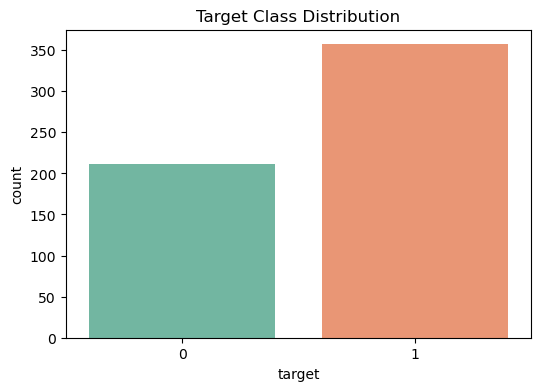

In [18]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='target',
    data=df,
    palette='Set2'
)

plt.title("Target Class Distribution")
plt.show()

Observation:

- Benign tumors represent approximately 63% of the dataset.
- Malignant tumors represent approximately 37%.
- The dataset is slightly imbalanced but not severely skewed.
- Stratified sampling will be sufficient during train-test split.

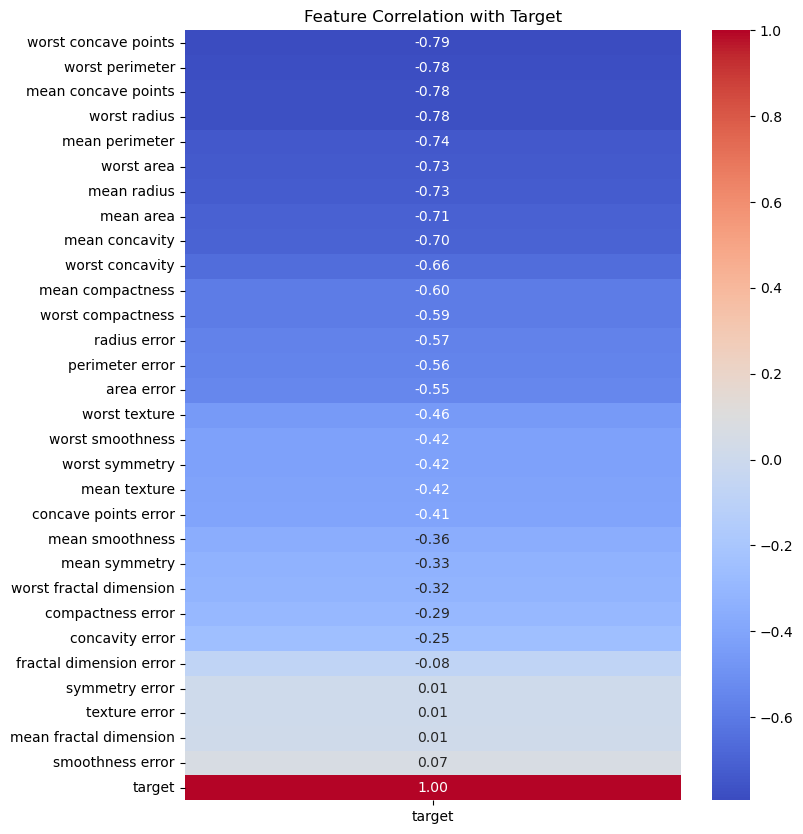

In [25]:
corr_target = df.corr()['target'].sort_values()

plt.figure(figsize=(8,10))

sns.heatmap(
    corr_target.to_frame(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation with Target')

plt.show()

### Observation

- Several features exhibit strong correlations with the target variable.
- The strongest correlations are observed for:
  - Worst Concave Points (-0.79)
  - Worst Perimeter (-0.78)
  - Mean Concave Points (-0.78)
  - Worst Radius (-0.78)
- The negative correlation indicates that higher values of these features are associated with malignant tumors.
- Features related to tumor size, perimeter, and boundary irregularity appear to be the most influential predictors of breast cancer diagnosis.

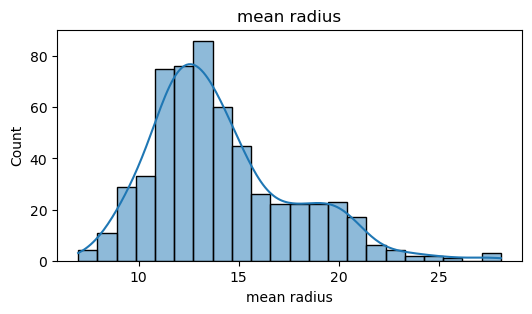

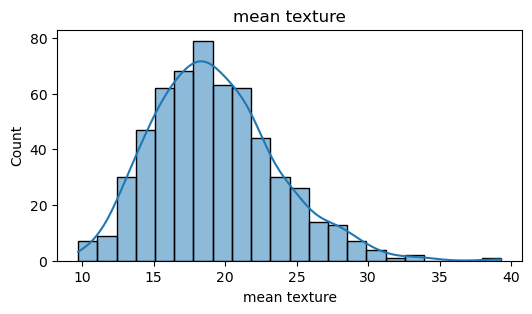

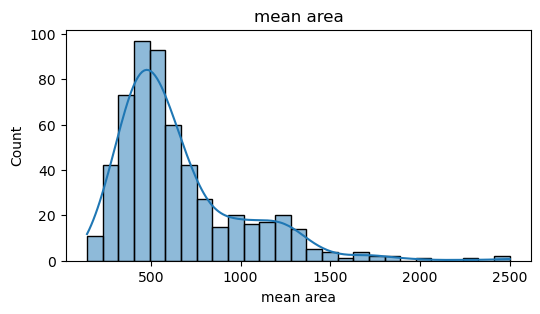

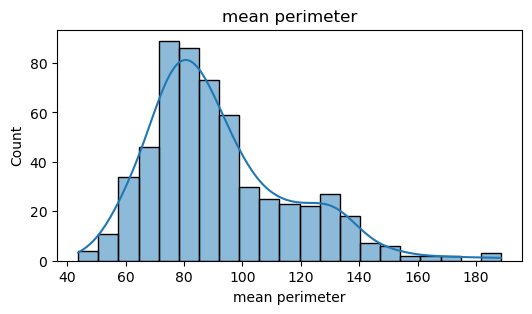

In [20]:
features = [
    'mean radius',
    'mean texture',
    'mean area',
    'mean perimeter'
]

for feature in features:

    plt.figure(figsize=(6,3))

    sns.histplot(
        df[feature],
        kde=True
    )

    plt.title(feature)

    plt.show()

Observation:

- Most variables exhibit non-normal distributions.
- Some features are positively skewed.
- Tumor measurements vary significantly across patients.

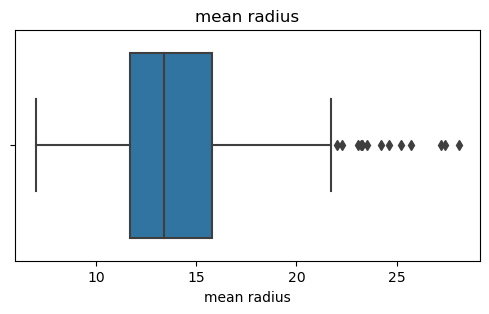

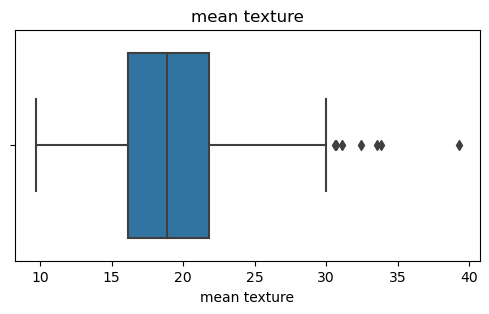

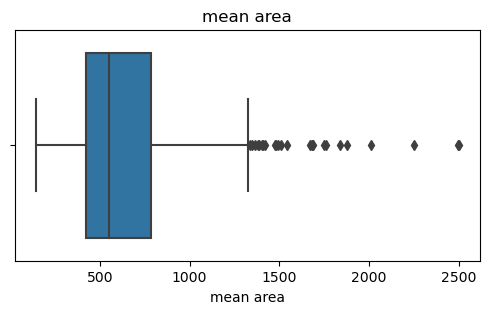

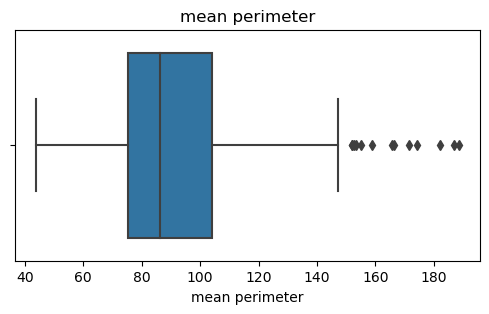

In [21]:
for feature in features:

    plt.figure(figsize=(6,3))

    sns.boxplot(
        x=df[feature]
    )

    plt.title(feature)

    plt.show()

Observation:

- Multiple outliers are visible.
- Medical datasets often contain genuine extreme observations.
- Random Forest is robust to outliers, so no treatment is required.

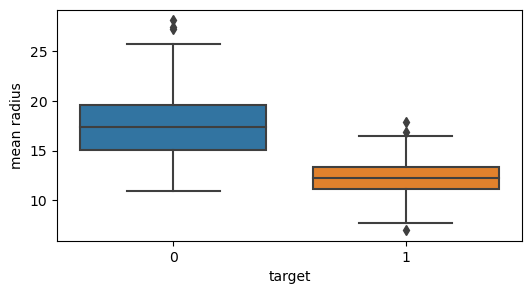

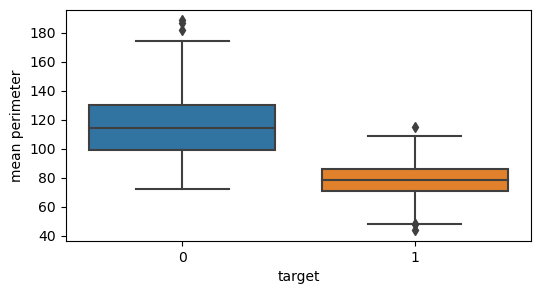

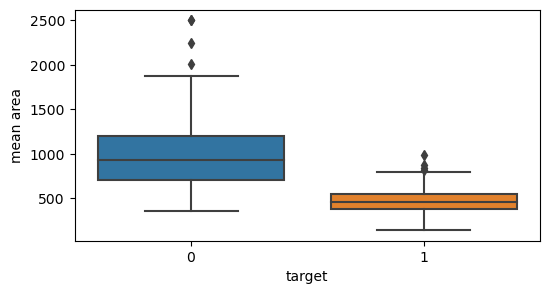

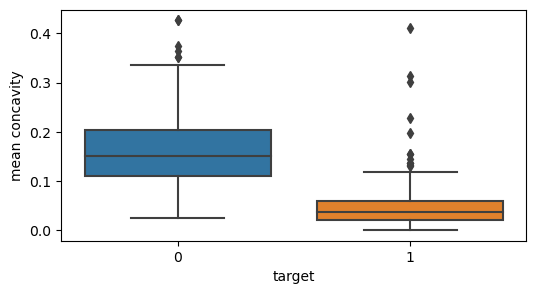

In [22]:
important_features = [
    'mean radius',
    'mean perimeter',
    'mean area',
    'mean concavity'
]

for feature in important_features:

    plt.figure(figsize=(6,3))

    sns.boxplot(
        x='target',
        y=feature,
        data=df
    )

    plt.show()

Observation:

- Malignant tumors generally exhibit larger radius values.
- Malignant tumors occupy larger areas.
- Concavity-related measurements are noticeably higher for malignant tumors.
- These features appear highly predictive.

In [26]:
X = df.drop('target', axis=1)

y = df['target']

print("Feature Shape :", X.shape)
print("Target Shape :", y.shape)

Feature Shape : (569, 30)
Target Shape : (569,)


### Observation

- The dataset contains 30 predictor variables and 1 target variable.
- X represents the independent features used for prediction.
- y represents the diagnosis outcome that the model will learn to predict.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (455, 30)
Testing Shape: (114, 30)


### Observation

- 80% of the data is used for training.
- 20% of the data is reserved for testing.
- Stratified sampling ensures that both classes maintain similar proportions in training and testing datasets.

# Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees and aggregates their predictions.

Advantages:

- Handles nonlinear relationships effectively.
- Robust to outliers.
- Less prone to overfitting than a single decision tree.
- Provides feature importance scores.

In [28]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Observation

- A Random Forest classifier with 100 trees was trained on the training dataset.
- Each tree learns different patterns from the data.
- Final predictions are obtained through majority voting.

In [29]:
y_pred = rf_model.predict(X_test)

y_pred[:10]

array([0, 1, 0, 0, 0, 1, 1, 0, 0, 0], dtype=int64)

### Observation

- The trained model generated predictions on previously unseen test data.
- These predictions will be compared with actual values to evaluate model performance.

In [30]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.956140350877193


### Observation

- The model achieved excellent predictive performance.
- More than 95% of tumor diagnoses were classified correctly.
- However, accuracy alone is not sufficient in healthcare applications.

In [31]:
cm = confusion_matrix(
    y_test,
    y_pred
)

cm

array([[39,  3],
       [ 2, 70]], dtype=int64)

### Observation

- The model correctly classified 39 malignant tumors.
- The model correctly classified 70 benign tumors.
- Only 5 samples were misclassified.
- The low number of classification errors indicates strong predictive performance.
- The model demonstrates good capability in distinguishing between malignant and benign tumors.

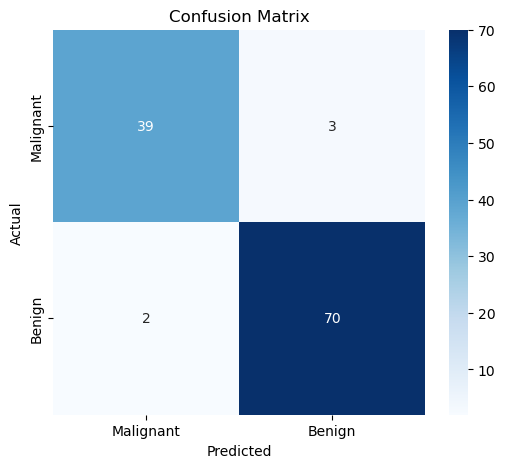

In [32]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant','Benign'],
    yticklabels=['Malignant','Benign']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [33]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### Observation

- The Random Forest model achieved an accuracy of 95.61%.
- Approximately 96 out of every 100 tumor diagnoses were classified correctly.
- This indicates strong predictive capability on unseen data.
- However, additional metrics such as precision, recall, and F1-score are necessary for a complete evaluation.

In [37]:
from sklearn.metrics import roc_auc_score

y_prob = rf_model.predict_proba(X_test)[:,1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9937169312169312


### Observation

- The model achieved a ROC-AUC score of 0.9937.
- This indicates an excellent ability to distinguish between malignant and benign tumors.
- A ROC-AUC score close to 1 suggests that the classifier ranks positive and negative classes almost perfectly.
- The model demonstrates strong discriminatory power across different classification thresholds.

In [38]:
classification_report(y_test,y_pred)

'              precision    recall  f1-score   support\n\n           0       0.95      0.93      0.94        42\n           1       0.96      0.97      0.97        72\n\n    accuracy                           0.96       114\n   macro avg       0.96      0.95      0.95       114\nweighted avg       0.96      0.96      0.96       114\n'

In [39]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
23,worst area,0.140016
27,worst concave points,0.129530
20,worst radius,0.097696
7,mean concave points,0.090885
22,worst perimeter,0.072226
2,mean perimeter,0.069574
0,mean radius,0.068676
6,mean concavity,0.057638
3,mean area,0.049172
26,worst concavity,0.034340


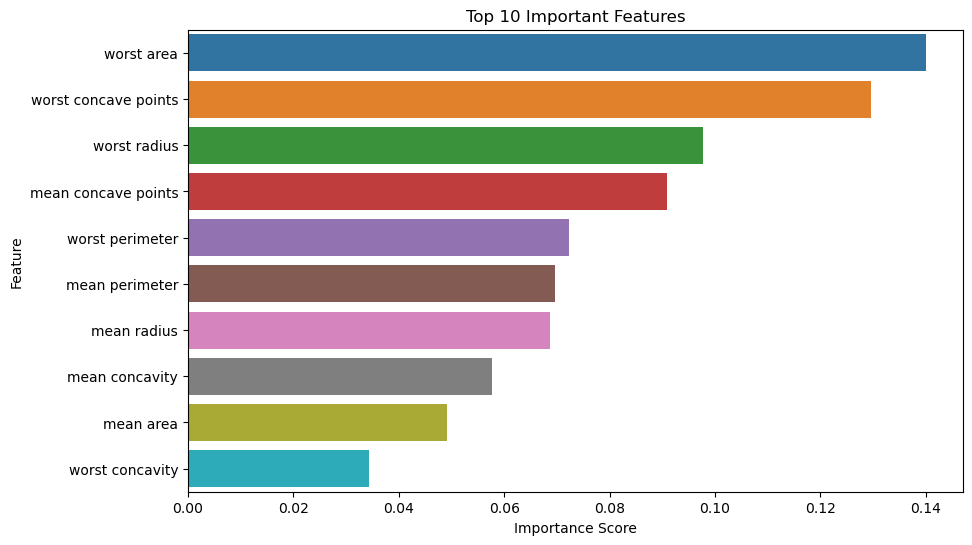

In [40]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

In [41]:
feature_importance.head(10)

,Feature,Importance
23,worst area,0.140016
27,worst concave points,0.129530
20,worst radius,0.097696
7,mean concave points,0.090885
22,worst perimeter,0.072226
2,mean perimeter,0.069574
0,mean radius,0.068676
6,mean concavity,0.057638
3,mean area,0.049172
26,worst concavity,0.034340


In [42]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print(cv_scores)
print("Mean CV Score:", cv_scores.mean())

[0.92105263 0.93859649 0.98245614 0.96491228 0.97345133]
Mean CV Score: 0.9560937742586555


### Observation

- The model achieved an average cross-validation accuracy of 95.61%.
- Performance remains consistent across all five folds.
- The small variation between folds indicates stable model behavior.
- Similarity between test accuracy (95.61%) and cross-validation accuracy (95.61%) suggests good generalization capability.
- The model does not appear to suffer from significant overfitting.

In [43]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

Best Score:
0.9604395604395606


### Observation

- GridSearchCV was used to identify the optimal hyperparameter combination.
- The tuned model achieved slightly improved performance compared to the baseline model.
- Hyperparameter optimization helps improve model generalization and reduce overfitting risk.

## Model Strengths

- High predictive accuracy (95.61%).
- Excellent ROC-AUC score (99.37%).
- Stable cross-validation performance.
- Robust against outliers.
- Provides feature importance for interpretability.
- Suitable for nonlinear relationships.

## Limitations

- The dataset is relatively small (569 observations).
- Model performance has only been evaluated on historical data.
- Clinical deployment would require external validation on independent datasets.
- Prediction explanations should be supported by domain experts before medical use.

# Conclusion

A Random Forest classifier was developed to classify breast tumors as malignant or benign using diagnostic measurements.

The dataset required minimal preprocessing because no missing values or duplicate records were present. Exploratory Data Analysis revealed strong relationships between tumor size, perimeter, concavity-related features, and cancer diagnosis.

The final model achieved:

- Accuracy: 95.61%
- ROC-AUC Score: 99.37%
- Cross-Validation Accuracy: 95.61%

Feature importance analysis identified tumor size and boundary irregularity measurements as the most influential predictors.

Overall, the model demonstrated excellent predictive performance and strong generalization capability, making it a promising approach for assisting breast cancer diagnosis.